# 26.04 Act 2: Customer lifetime value, Online Retail II
Question: how many orders will each customer place over the next 12 months, how much will each order be worth, and where does the money sit?
Two models do the work. BG/NBD predicts the number of future orders (it allows a customer to quietly leave at any moment). Gamma-Gamma predicts the value of an order. Multiply them and you get a customer lifetime value (CLV).
Everything here is revenue in GBP, not profit: the file has no cost data.
Out of scope: segment budget allocation (Act 3).

In [1]:
import zipfile, os
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import calibration_and_holdout_data, summary_data_from_transaction_data
from lifetimes.plotting import plot_calibration_purchases_vs_holdout_purchases
%matplotlib inline

np.random.seed(42)
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # run from the repo root so data/ and outputs/ resolve
os.makedirs("outputs", exist_ok=True)
T_END = pd.Timestamp("2011-12-09")          # last date in the file
HOLDOUT_DAYS = 180                          # validation window: hide the last 180 days, predict them
CAL_END = T_END - pd.Timedelta(f"{HOLDOUT_DAYS}D")
HORIZON_MONTHS = 12                         # the CLV horizon, a stated choice (sensitivity in step 9)
DISCOUNT_ANNUAL = 0.10                      # money later is worth less; 10 percent a year, a stated choice
DISC_MONTHLY = (1 + DISCOUNT_ANNUAL) ** (1 / 12) - 1
LOG = {}
print("calibration ends", CAL_END.date(), "| holdout", HOLDOUT_DAYS, "days | horizon", HORIZON_MONTHS, "months")

calibration ends 2011-06-12 | holdout 180 days | horizon 12 months


/tmp/ipykernel_12688/2405257266.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  CAL_END = T_END - pd.Timedelta(f"{HOLDOUT_DAYS}D")


## Step 1. Same cleaned order table as Act 1
The cleaning rules are identical to Act 1 (no Customer ID, cancellations, non-positive quantity or price, non-product codes), so the two acts describe the same customers. Counts are printed so they can be checked against Act 1's DATA.md.

In [2]:
PKL = "data/retail_raw.pkl"
if os.path.exists(PKL):
    raw = pd.read_pickle(PKL)
else:
    with zipfile.ZipFile("data/online_retail_II.zip") as z:
        xl = [n for n in z.namelist() if n.endswith(".xlsx")][0]
        z.extract(xl, "data")
    raw = pd.concat(pd.read_excel(os.path.join("data", xl), sheet_name=None).values(), ignore_index=True)
    raw.to_pickle(PKL)
print("raw rows:", len(raw))
df = raw.loc[raw["Customer ID"].notna()].copy()
df["Customer ID"] = df["Customer ID"].astype(int)
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
NON_PRODUCT = {"POST","D","M","C2","BANK CHARGES","ADJUST","ADJUST2","S","AMAZONFEE","DOT","CRUK","TEST001","TEST002","PADS","B"}
for name, f in [("cancellation invoice", lambda d: d["Invoice"].str.startswith("C")),
                ("Quantity <= 0",        lambda d: d["Quantity"] <= 0),
                ("Price <= 0",           lambda d: d["Price"] <= 0),
                ("non-product StockCode",lambda d: d["StockCode"].str.upper().isin(NON_PRODUCT))]:
    m = f(df); print(f"{name}: removed {m.sum():,}"); df = df.loc[~m]
df["Date"] = df["InvoiceDate"].dt.normalize()
df["Revenue"] = df["Quantity"] * df["Price"]
print("clean rows:", len(df))
LOG["clean_rows"] = len(df)

raw rows: 1067371


cancellation invoice: removed 18,744
Quantity <= 0: removed 0
Price <= 0: removed 71
non-product StockCode: removed 2,915


clean rows: 802634


## Step 2. One row per customer per order day
An order is every invoice a customer placed on one calendar day, added together. This matches Act 1, where gaps were measured between distinct order days. It is the unit BG/NBD counts, so "frequency" below means repeat order days.
Value is the sum of Quantity x Price for that day, in GBP.

In [3]:
tx = (df.groupby(["Customer ID", "Date"], as_index=False)["Revenue"].sum()
        .rename(columns={"Revenue": "Value"}))
print("order days:", len(tx), "| customers:", tx["Customer ID"].nunique())
print(tx["Value"].describe().round(1))
LOG["order_days"] = len(tx); LOG["customers"] = int(tx["Customer ID"].nunique())

order days: 32878 | customers: 5852
count     32878.0
mean        530.3
std        1591.0
min           0.4
25%         183.6
50%         314.4
75%         516.1
max      168469.6
Name: Value, dtype: float64


## Step 3. Split time in two: calibration and holdout
Fit on everything up to the calibration end, then ask the model to predict the last 180 days it never saw. This is the only honest test of a CLV number: an unvalidated CLV figure is a guess wearing a formula.
For each customer the table holds: frequency (repeat order days), recency (days from first to last order), T (days from first order to calibration end), and average order value of repeat orders. Customers whose first order falls after the calibration end are not in the table, they cannot be predicted.

In [4]:
cal = calibration_and_holdout_data(tx, "Customer ID", "Date",
        calibration_period_end=CAL_END, observation_period_end=T_END,
        freq="D", monetary_value_col="Value")
print("customers in calibration:", len(cal))
print("repeaters (2+ order days in calibration):", int((cal["frequency_cal"] > 0).sum()),
      f"= {(cal['frequency_cal'] > 0).mean():.1%}")
print("holdout: customers who ordered at least once:", int((cal["frequency_holdout"] > 0).sum()),
      f"= {(cal['frequency_holdout'] > 0).mean():.1%}")
print("holdout window days:", int(cal["duration_holdout"].iloc[0]))
cal.describe().T[["mean", "50%", "max"]].round(2)

customers in calibration: 4952
repeaters (2+ order days in calibration): 3345 = 67.5%
holdout: customers who ordered at least once: 2571 = 51.9%
holdout window days: 180


,mean,50%,max
frequency_cal,3.73,1.00,165.00
recency_cal,193.86,153.00,558.00
T_cal,365.41,401.00,558.00
monetary_value_cal,286.37,200.39,38662.96
frequency_holdout,1.55,1.00,81.00
monetary_value_holdout,264.61,81.72,168469.60
duration_holdout,180.00,180.00,180.00


## Step 4. BG/NBD: how many orders to expect
BG/NBD assumes each customer orders at their own steady rate while "alive", and after any order may quietly become inactive with some probability. Nobody announces it, so the model infers it from silence. The four fitted numbers (r, alpha, a, b) describe how rates and drop-out vary across customers.

In [5]:
bgf = BetaGeoFitter(penalizer_coef=0.001)
bgf.fit(cal["frequency_cal"], cal["recency_cal"], cal["T_cal"])
print(bgf.summary.round(4))
print("mean probability alive at calibration end:",
      round(bgf.conditional_probability_alive(cal["frequency_cal"], cal["recency_cal"], cal["T_cal"]).mean(), 3))

          coef  se(coef)  lower 95% bound  upper 95% bound
r       0.6848    0.0190           0.6477           0.7220
alpha  66.3616    2.3041          61.8456          70.8776
a       0.0856    0.0109           0.0643           0.1070
b       1.2751    0.1755           0.9310           1.6192
mean probability alive at calibration end: 0.908


## Step 5. Did the BG/NBD forecast hold up on the 180 days it never saw?
Three checks, from coarse to fine: total orders predicted versus actual, a naive baseline (assume each customer keeps their past order rate), and a decile table of customers ranked by predicted orders.

    BG/NBD: total     7570 vs actual 7699 (-1.7%) | per-customer correlation 0.849 | mean abs error 1.037
     naive: total     7978 vs actual 7699 (+3.6%) | per-customer correlation 0.813 | mean abs error 1.073
        customers  predicted  actual    gap
decile                                     
1             496      0.221   0.181  0.039
2             495      0.332   0.293  0.039
3             495      0.428   0.453 -0.025
4             495      0.565   0.457  0.109
5             495      0.761   0.772 -0.011
6             495      1.003   0.994  0.009
7             495      1.329   1.360 -0.031
8             495      1.761   1.794 -0.032
9             495      2.625   2.477  0.148
10            496      6.256   6.760 -0.504


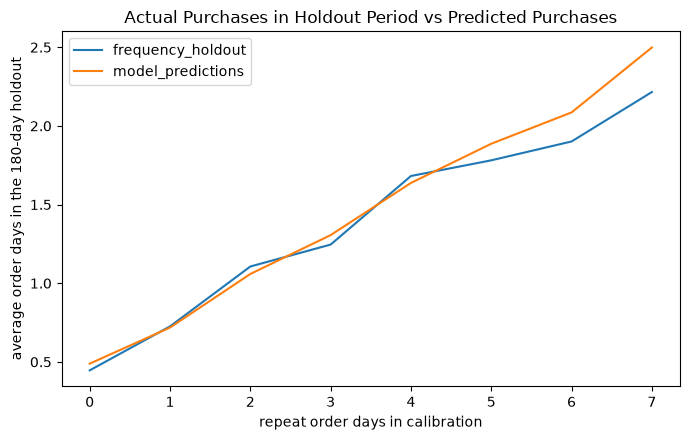

In [6]:
cal["pred_orders"] = bgf.conditional_expected_number_of_purchases_up_to_time(
    cal["duration_holdout"], cal["frequency_cal"], cal["recency_cal"], cal["T_cal"])
# naive baseline: repeat orders per day in calibration x holdout days (a customer with no repeats gets 0)
cal["naive_orders"] = (cal["frequency_cal"] / cal["T_cal"].replace(0, np.nan)).fillna(0) * cal["duration_holdout"]
act = cal["frequency_holdout"]
def rep(label, p):
    print(f"{label:>10}: total {p.sum():8.0f} vs actual {act.sum():.0f} ({p.sum()/act.sum()-1:+.1%}) | "
          f"per-customer correlation {np.corrcoef(p, act)[0,1]:.3f} | mean abs error {np.abs(p-act).mean():.3f}")
rep("BG/NBD", cal["pred_orders"]); rep("naive", cal["naive_orders"])
cal["decile"] = pd.qcut(cal["pred_orders"].rank(method="first"), 10, labels=False) + 1
t = cal.groupby("decile").agg(customers=("pred_orders", "size"), predicted=("pred_orders", "mean"), actual=("frequency_holdout", "mean"))
t["gap"] = (t["predicted"] - t["actual"]).round(3)
print(t.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_calibration_purchases_vs_holdout_purchases(bgf, cal, n=8, ax=ax)
ax.set_xlabel("repeat order days in calibration"); ax.set_ylabel("average order days in the 180-day holdout")
fig.tight_layout(); fig.savefig("outputs/05_calibration_vs_holdout.png", dpi=150); plt.show()

## Step 6. Gamma-Gamma: what an order is worth, and whether to trust it
Gamma-Gamma estimates a customer's typical order value by pulling a thin history toward the population average. It needs two things to hold. First, order value must not depend on how often the customer orders: the check is the correlation between frequency and average order value among repeaters. Second, its fitted shape parameter q must be above 1, otherwise the population mean order value is not defined and the shrinkage target is meaningless. It is fitted only on customers with at least one repeat order.
This step tests both and also compares the model with the plain average of a customer's own repeat orders, which is the simple alternative.

In [7]:
rep_c = cal[(cal["frequency_cal"] > 0) & (cal["monetary_value_cal"] > 0)].copy()
corr = rep_c[["frequency_cal", "monetary_value_cal"]].corr().iloc[0, 1]
print(f"repeaters used: {len(rep_c):,} | correlation frequency vs average order value: {corr:.3f}")
ggf = GammaGammaFitter(penalizer_coef=0.001)
ggf.fit(rep_c["frequency_cal"], rep_c["monetary_value_cal"])
print(ggf.summary.round(4))
p_, q_, v_ = ggf.params_["p"], ggf.params_["q"], ggf.params_["v"]
print(f"q = {q_:.3f}  (needs to be above 1 for the population mean order value to exist; implied mean = {v_*p_/(q_-1):,.0f})")
rep_c["gg_aov"] = ggf.conditional_expected_average_profit(rep_c["frequency_cal"], rep_c["monetary_value_cal"])
hold = rep_c[rep_c["frequency_holdout"] > 0]
print(f"repeaters who ordered in holdout: {len(hold):,}")
print(f"average order value in holdout: actual {hold['monetary_value_holdout'].mean():.1f} | Gamma-Gamma {hold['gg_aov'].mean():.1f} | own calibration average {hold['monetary_value_cal'].mean():.1f}")
print("per-customer correlation with holdout order value: Gamma-Gamma", round(np.corrcoef(hold["gg_aov"], hold["monetary_value_holdout"])[0,1], 3),
      "| own average", round(np.corrcoef(hold["monetary_value_cal"], hold["monetary_value_holdout"])[0,1], 3))
LOG["gg_corr"] = float(corr); LOG["gg_q"] = float(q_)

repeaters used: 3,345 | correlation frequency vs average order value: 0.084


      coef  se(coef)  lower 95% bound  upper 95% bound
p  11.8123    0.2528          11.3168          12.3078
q   0.8769    0.0188           0.8401           0.9138
v  11.7474    0.2580          11.2418          12.2531
q = 0.877  (needs to be above 1 for the population mean order value to exist; implied mean = -1,128)
repeaters who ordered in holdout: 2,148
average order value in holdout: actual 459.4 | Gamma-Gamma 445.5 | own calibration average 439.8
per-customer correlation with holdout order value: Gamma-Gamma 0.835 | own average 0.835


Reading of step 6: if q is at or below 1 the model's own assumption fails on this data (very uneven order sizes: some wholesale buyers place orders hundreds of times larger than the typical one). In that case the plain average of a customer's repeat orders is used for CLV below, and Gamma-Gamma stays in the notebook as a documented test, not as the engine.

## Step 7. The dollar check: predicted holdout revenue versus actual
Put the two models together on the holdout: expected orders x expected order value. Order value per customer is their own average repeat order. Customers with no repeat order have no value history, so they get the repeater average. Actual revenue is what the customer really spent in the 180 days.

In [8]:
pop_aov = float(rep_c["monetary_value_cal"].mean())     # customers with no repeat order get the repeater average
cal["pred_aov"] = pop_aov
cal.loc[rep_c.index, "pred_aov"] = rep_c["monetary_value_cal"]
cal["pred_rev"] = cal["pred_orders"] * cal["pred_aov"]
cal["act_rev"] = (cal["frequency_holdout"] * cal["monetary_value_holdout"]).fillna(0)
print(f"total holdout revenue: predicted {cal['pred_rev'].sum():,.0f} vs actual {cal['act_rev'].sum():,.0f} ({cal['pred_rev'].sum()/cal['act_rev'].sum()-1:+.1%})")
print("per-customer correlation:", round(np.corrcoef(cal["pred_rev"], cal["act_rev"])[0,1], 3),
      "| rank correlation:", round(cal["pred_rev"].corr(cal["act_rev"], method="spearman"), 3))
top = cal["pred_rev"].rank(ascending=False, method="first") <= len(cal) * 0.10
print(f"predicted top 10 percent of customers earned {cal.loc[top,'act_rev'].sum()/cal['act_rev'].sum():.1%} of actual holdout revenue (random pick would be 10%)")
cal["rev_decile"] = pd.qcut(cal["pred_rev"].rank(method="first"), 10, labels=False) + 1
d = cal.groupby("rev_decile").agg(predicted=("pred_rev", "sum"), actual=("act_rev", "sum"))
d["pred_share"] = d["predicted"] / d["predicted"].sum(); d["actual_share"] = d["actual"] / d["actual"].sum()
print(d.round(3).to_string())
hx = tx[tx["Date"] > CAL_END]["Value"].sort_values(ascending=False)
print(f"largest single order in the holdout: {hx.iloc[0]:,.0f} ({hx.iloc[0]/cal['act_rev'].sum():.1%} of holdout revenue); actual without it {cal['act_rev'].sum()-hx.iloc[0]:,.0f}; predicted is {cal['pred_rev'].sum()/(cal['act_rev'].sum()-hx.iloc[0])-1:+.1%} against that")
LOG["val_total_pred"] = float(cal["pred_rev"].sum()); LOG["val_total_act"] = float(cal["act_rev"].sum()); LOG["val_big"] = float(hx.iloc[0])

total holdout revenue: predicted 3,779,301 vs actual 4,510,530 (-16.2%)
per-customer correlation: 0.818 | rank correlation: 0.608
predicted top 10 percent of customers earned 61.3% of actual holdout revenue (random pick would be 10%)
              predicted      actual  pred_share  actual_share
rev_decile                                                   
1             30966.871    34518.39       0.008         0.008
2             52054.710    40001.86       0.014         0.009
3             69986.485    74213.56       0.019         0.016
4             87488.772   108074.39       0.023         0.024
5            115584.738   117455.62       0.031         0.026
6            159332.392   144368.87       0.042         0.032
7            218047.406   193023.62       0.058         0.043
8            313489.179   478054.49       0.083         0.106
9            516540.206   552900.71       0.137         0.123
10          2215810.302  2767918.82       0.586         0.614
largest single order i

## Step 8. Refit on all data and compute CLV
Same BG/NBD, now fitted on every order up to 2011-12-09. Order value is each customer's own average repeat order (Gamma-Gamma failed its test in step 6), customers with no repeat order get the repeater average. CLV is expected orders over the stated horizon x order value, month by month, each month discounted. The horizon (12 months) and the discount rate (10 percent a year) are choices, not facts; step 9 shows how the answer moves with the horizon.

In [9]:
full = summary_data_from_transaction_data(tx, "Customer ID", "Date", observation_period_end=T_END,
                                          freq="D", monetary_value_col="Value")
bgf2 = BetaGeoFitter(penalizer_coef=0.001).fit(full["frequency"], full["recency"], full["T"])
print(bgf2.summary.round(4))
POP_AOV = float(full.loc[full["frequency"] > 0, "monetary_value"].mean())
full["aov"] = np.where(full["frequency"] > 0, full["monetary_value"], POP_AOV)
def clv(months):
    out = pd.Series(0.0, index=full.index)
    for m in range(1, months + 1):
        n = (bgf2.predict(30 * m, full["frequency"], full["recency"], full["T"])
             - bgf2.predict(30 * (m - 1), full["frequency"], full["recency"], full["T"]))
        out += full["aov"] * n / (1 + DISC_MONTHLY) ** m
    return out
full["p_alive"] = bgf2.conditional_probability_alive(full["frequency"], full["recency"], full["T"])
full["clv"] = clv(HORIZON_MONTHS)
print(f"customers: {len(full):,} | total {HORIZON_MONTHS}-month CLV: {full['clv'].sum():,.0f} | median {full['clv'].median():,.0f} | mean {full['clv'].mean():,.0f}")
print("customers with CLV below 0 or NaN:", int((full['clv'] < 0).sum() + full['clv'].isna().sum()))

          coef  se(coef)  lower 95% bound  upper 95% bound
r       0.6708    0.0160           0.6394           0.7023
alpha  63.7407    1.9546          59.9097          67.5717
a       0.0742    0.0076           0.0594           0.0890
b       1.2294    0.1509           0.9336           1.5253
customers: 5,852 | total 12-month CLV: 8,888,115 | median 516 | mean 1,519
customers with CLV below 0 or NaN: 0


## Step 9. The horizon is a choice: what changes if it doubles
If the horizon doubled, would the CLV double? Only if every customer stayed alive and active forever at the same rate. BG/NBD lets customers leave and the discount rate shrinks later money, so the total grows by less than double.

In [10]:
rows = []
for h in (6, 12, 24):
    c = clv(h)
    s = c.sort_values(ascending=False)
    rows.append({"months": h, "total_clv": c.sum(), "mean_clv": c.mean(), "top10pct_share": s.head(int(len(s)*0.1)).sum() / s.sum()})
H = pd.DataFrame(rows); H["total_vs_12m"] = H["total_clv"] / H.loc[H["months"] == 12, "total_clv"].iloc[0]
print(H.round(3).to_string(index=False))
LOG["horizon"] = H.to_dict("records")

 months    total_clv  mean_clv  top10pct_share  total_vs_12m
      6  4599342.176   785.944           0.602         0.517
     12  8888115.021  1518.817           0.603         1.000
     24 16698624.897  2853.490           0.604         1.879


## Step 10. CLV tiers and concentration
Quartiles by 12-month CLV, ranked so that ties cannot split a tier unevenly. The number a retention budget is built around is the top tier's share of total value.

           customers    total_clv  mean_clv  mean_p_alive  mean_repeat_orders  share_of_value
tier                                                                                         
Q1 lowest       1463   200703.902   137.187         0.814               1.111           0.023
Q2              1463   483828.489   330.710         0.900               1.592           0.054
Q3              1463  1225129.641   837.409         0.950               3.285           0.138
Q4 top          1463  6978452.989  4769.961         0.971              12.485           0.785
top 1% of customers hold 31.0% of 12-month CLV
top 5% of customers hold 48.7% of 12-month CLV
top 10% of customers hold 60.3% of 12-month CLV
top 20% of customers hold 73.9% of 12-month CLV


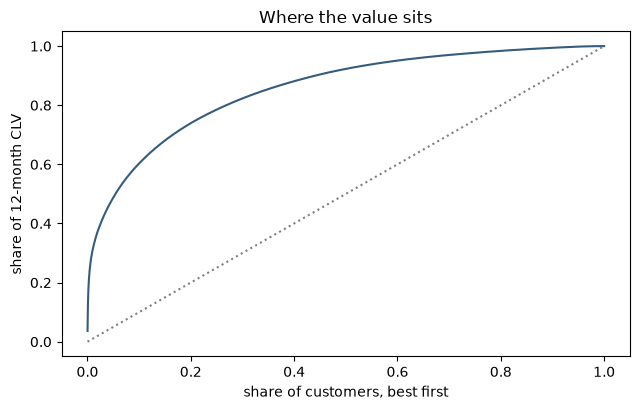

In [11]:
full["tier"] = pd.qcut(full["clv"].rank(method="first"), 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 top"])
t = full.groupby("tier", observed=True).agg(customers=("clv", "size"), total_clv=("clv", "sum"), mean_clv=("clv", "mean"),
                                           mean_p_alive=("p_alive", "mean"), mean_repeat_orders=("frequency", "mean"))
t["share_of_value"] = t["total_clv"] / t["total_clv"].sum()
print(t.round(3).to_string())
s = full["clv"].sort_values(ascending=False)
for q in (0.01, 0.05, 0.10, 0.20):
    print(f"top {q:.0%} of customers hold {s.head(int(len(s)*q)).sum()/s.sum():.1%} of 12-month CLV")
cum = s.cumsum() / s.sum()
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(np.arange(1, len(s) + 1) / len(s), cum.values, color="#355c7d")
ax.plot([0, 1], [0, 1], color="grey", ls=":")
ax.set_xlabel("share of customers, best first"); ax.set_ylabel("share of 12-month CLV")
ax.set_title("Where the value sits")
fig.tight_layout(); fig.savefig("outputs/06_clv_concentration.png", dpi=150); plt.show()
LOG["tiers"] = t.reset_index().astype({"tier": str}).to_dict("records")
LOG["top10"] = float(s.head(int(len(s)*0.1)).sum()/s.sum()); LOG["total_clv"] = float(s.sum())

## Step 11. Cross-check against Act 1
Act 1 labelled a customer churned after N days of silence (N = the 90th percentile gap). BG/NBD never sees that label, it only sees order history. If both are sensible they should broadly agree: customers Act 1 calls churned should have a low probability of being alive here.

In [12]:
days = tx.sort_values(["Customer ID", "Date"]).copy()
days["gap"] = days.groupby("Customer ID")["Date"].diff().dt.days
N = int(round(np.percentile(days["gap"].dropna(), 90)))
last = tx.groupby("Customer ID")["Date"].max()
full["act1_churned"] = ((last + pd.Timedelta(f"{N}D")) <= T_END).reindex(full.index)
x = full.groupby("act1_churned").agg(customers=("p_alive", "size"), mean_p_alive=("p_alive", "mean"),
                                    share_below_half=("p_alive", lambda v: (v < 0.5).mean()), mean_clv=("clv", "mean"))
print("N =", N); print(x.round(3).to_string())

N = 148
              customers  mean_p_alive  share_below_half  mean_clv
act1_churned                                                     
False              3271         0.971             0.000  2459.459
True               2581         0.830             0.114   326.705


/tmp/ipykernel_12688/4058461443.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  full["act1_churned"] = ((last + pd.Timedelta(f"{N}D")) <= T_END).reindex(full.index)


## Step 12. DATA.md

In [13]:
marker = "## Act 2"
base = open("DATA.md").read().split(marker)[0].rstrip() + "\n\n"
sec = [marker + ": CLV (BG/NBD + Gamma-Gamma)", "",
 "- Same source, licence and cleaning as Act 1 (rules above); clean rows: {:,}".format(LOG["clean_rows"]),
 "- Unit: one customer, one order day; order days {:,}, customers {:,}".format(LOG["order_days"], LOG["customers"]),
 f"- Calibration ends {CAL_END.date()}, holdout {HOLDOUT_DAYS} days to {T_END.date()}",
 f"- Horizon {HORIZON_MONTHS} months, discount {DISCOUNT_ANNUAL:.0%} a year, revenue in GBP (no cost data, so not profit)",
 f"- Gamma-Gamma independence check: correlation of frequency and average order value among repeaters = {LOG['gg_corr']:.3f}",
 f"- Holdout revenue: predicted {LOG['val_total_pred']:,.0f} vs actual {LOG['val_total_act']:,.0f}",
 f"- Total {HORIZON_MONTHS}-month CLV {LOG['total_clv']:,.0f}; top 10 percent of customers hold {LOG['top10']:.1%}"]
open("DATA.md", "w").write(base + "\n".join(sec) + "\n")
print(open("DATA.md").read()[-900:])

12-09, churn window N = 148 days (90th percentile gap), sensitivity at the 75th and 95th
- New-customer cutoff: first order on or after 2010-06-01, removed 2,684 customers
- First 30 days must be fully observed before T_end, removed 152 customers
- Customers modelled: 3,016
- Gaps are measured between distinct order days

## Act 2: CLV (BG/NBD + Gamma-Gamma)

- Same source, licence and cleaning as Act 1 (rules above); clean rows: 802,634
- Unit: one customer, one order day; order days 32,878, customers 5,852
- Calibration ends 2011-06-12, holdout 180 days to 2011-12-09
- Horizon 12 months, discount 10% a year, revenue in GBP (no cost data, so not profit)
- Gamma-Gamma independence check: correlation of frequency and average order value among repeaters = 0.084
- Holdout revenue: predicted 3,779,301 vs actual 4,510,530
- Total 12-month CLV 8,888,115; top 10 percent of customers hold 60.3%



## Limitations
1. This is revenue, not profit, and not even net revenue. The file has no costs, and cancellations were removed rather than netted off, so a customer who returns goods still counts in full. A CLV in GBP revenue cannot be compared with an acquisition cost until margin and returns are added.
2. Order sizes are very uneven and that breaks the order-value model. Gamma-Gamma needs its shape parameter q above 1 and got 0.88, so its population mean is undefined and it gave no better ranking than a customer's own average (both 0.835). The forecast then undershoots holdout revenue by about 16 percent (13 percent without one 168,470 GBP order), and the top 1 percent of customers hold 31 percent of the 12-month CLV. A handful of wholesale accounts decide the total.
3. The validation covers one 180-day window that contains the Christmas peak, so the 6-month check is not a check of the 12-month or 24-month figure. Also, BG/NBD and Act 1 disagree: customers that Act 1 calls churned (148 days of silence) still average a 0.83 probability of being alive here, because BG/NBD decays belief smoothly instead of using a cut-off. Neither is the true answer, they are two definitions.